use the very exact priors for the deactivation prameters to check whether the model is setup correctly.

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
from HSA_Mo_C_002_pyro import (
    kinetics_model,
    TRUE_PARAMS,
    calculate_partial_pressures,
    generate_synthetic_data,
    run_variational_inference,
    predict,
    sample_prior,
)

In [3]:
Ts = torch.tensor([500, 550, 600]).reshape(-1, 1)
ps = torch.tensor([1.0, 0.5, 0.2]).reshape(-1, 1)
c2h = torch.tensor([1.0, 1.0, 1.0]).reshape(-1, 1)
c2m = torch.tensor([1.0, 1.0, 1.0]).reshape(-1, 1)
c2w = torch.tensor([1.0, 1.0, 1.0]).reshape(-1, 1)
c2i = torch.tensor([0.5, 0.5, 0.5]).reshape(-1, 1)

pi = calculate_partial_pressures(ps, c2h, c2m, c2w, c2i)

In [4]:
T_range = np.array([450, 600])
p_range = np.array([3, 9])
c2h_range = np.array([0.2, 4])
c2m_range = np.array([0.5, 1000])
c2w_range = np.array([0.5, 1000])
c2i_range = np.array([0.05, 1])

Tgrid, pgrid, c2hgrid, c2mgrid, c2wgrid, c2igrid = np.meshgrid(
    T_range, p_range, c2h_range, c2m_range, c2w_range, c2i_range
)

proposals = np.vstack(
    [
        Tgrid.ravel(),
        pgrid.ravel(),
        c2hgrid.ravel(),
        c2mgrid.ravel(),
        c2wgrid.ravel(),
        c2igrid.ravel(),
    ]
).T
proposals.shape  # Should be (64, 6) for a full factorial design with

(64, 6)

In [5]:
from scipy.stats import qmc

sampler = qmc.LatinHypercube(d=6)
sample = sampler.random(n=100)

# Scale samples to the appropriate ranges
T_lhs = qmc.scale(sample[:, 0:1], T_range[0], T_range[1])
p_lhs = qmc.scale(sample[:, 1:2], p_range[0], p_range[1])
c2h_lhs = qmc.scale(sample[:, 2:3], c2h_range[0], c2h_range[1])
c2m_lhs = qmc.scale(sample[:, 3:4], c2m_range[0], c2m_range[1])
c2w_lhs = qmc.scale(sample[:, 4:5], c2w_range[0], c2w_range[1])
c2i_lhs = qmc.scale(sample[:, 5:6], c2i_range[0], c2i_range[1])

proposals = np.column_stack([T_lhs, p_lhs, c2h_lhs, c2m_lhs, c2w_lhs, c2i_lhs])
print(proposals.shape)

(100, 6)


In [6]:
Ts = torch.tensor(proposals[:, 0]).reshape(-1, 1)
ps = torch.tensor(proposals[:, 1]).reshape(-1, 1)
c2hs = torch.tensor(proposals[:, 2]).reshape(-1, 1)
c2ms = torch.tensor(proposals[:, 3]).reshape(-1, 1)
c2ws = torch.tensor(proposals[:, 4]).reshape(-1, 1)
c2is = torch.tensor(proposals[:, 5]).reshape(-1, 1)
pi = calculate_partial_pressures(ps, c2hs, c2ms, c2ws, c2is)

In [7]:
print(Ts.shape)
print(pi.shape)
kinetics_model(pi, Ts, *TRUE_PARAMS.values()).shape

torch.Size([100, 1])
torch.Size([100, 5])


torch.Size([10, 100, 1, 1])

For one parameter set it seems to work.
We should check whether broadcasting was correct.

In [8]:
for idx_to_test in range(pi.shape[0]):
    kinetics_model(
        pi[idx_to_test : idx_to_test + 1, :],
        Ts[idx_to_test : idx_to_test + 1, :],
        *TRUE_PARAMS.values(),
    ).shape
    single_sol = kinetics_model(
        pi[idx_to_test : idx_to_test + 1, :],
        Ts[idx_to_test : idx_to_test + 1, :],
        *TRUE_PARAMS.values(),
    )[:, 0, 0, 0]
    batched_sol = kinetics_model(pi, Ts, *TRUE_PARAMS.values())[:, idx_to_test, 0, 0]
    isclose = torch.allclose(single_sol, batched_sol)
    print(
        f"Index {idx_to_test}: single solution shape {single_sol.shape}, batched solution shape {batched_sol.shape}, close: {isclose}"
    )
    print(single_sol)
    print(batched_sol)

Index 0: single solution shape torch.Size([10]), batched solution shape torch.Size([10]), close: True
tensor([1.0750e-04, 1.0022e-04, 9.3869e-05, 8.8273e-05, 8.3306e-05, 7.8869e-05,
        7.4880e-05, 7.1275e-05, 6.8002e-05, 6.5016e-05], dtype=torch.float64)
tensor([1.0750e-04, 1.0022e-04, 9.3869e-05, 8.8273e-05, 8.3306e-05, 7.8869e-05,
        7.4880e-05, 7.1275e-05, 6.8002e-05, 6.5016e-05], dtype=torch.float64)
Index 1: single solution shape torch.Size([10]), batched solution shape torch.Size([10]), close: True
tensor([1.2108e-04, 1.0833e-04, 9.8001e-05, 8.9472e-05, 8.2309e-05, 7.6208e-05,
        7.0949e-05, 6.6369e-05, 6.2345e-05, 5.8780e-05], dtype=torch.float64)
tensor([1.2108e-04, 1.0833e-04, 9.8001e-05, 8.9472e-05, 8.2309e-05, 7.6208e-05,
        7.0949e-05, 6.6369e-05, 6.2344e-05, 5.8780e-05], dtype=torch.float64)
Index 2: single solution shape torch.Size([10]), batched solution shape torch.Size([10]), close: True
tensor([5.0151e-05, 4.7137e-05, 4.4466e-05, 4.2081e-05, 3.9939

Brodcasting across samples works.
Now check broadcasting across draw dimension:

In [9]:
kinetics_model(
    pi,
    Ts,
    TRUE_PARAMS["k0"] * torch.tensor([[0.8, 0.9, 1.0, 1.2]]),
    TRUE_PARAMS["EA"].reshape(1, -1).repeat(1, 4),
    TRUE_PARAMS["k_deact"].reshape(1, -1).repeat(1, 4),
    TRUE_PARAMS["EA_deact"].reshape(1, -1).repeat(1, 4),
    TRUE_PARAMS["n_deact"].reshape(1, -1).repeat(1, 4),
).shape

torch.Size([10, 100, 1, 4])

In [10]:
k0s = TRUE_PARAMS["k0"] * torch.tensor([[0.8, 0.9, 1.0, 1.2]])

batched_sol = kinetics_model(
    pi,
    Ts,
    k0s,
    TRUE_PARAMS["EA"].reshape(1, -1).repeat(1, 4),
    TRUE_PARAMS["k_deact"].reshape(1, -1).repeat(1, 4),
    TRUE_PARAMS["EA_deact"].reshape(1, -1).repeat(1, 4),
    TRUE_PARAMS["n_deact"].reshape(1, -1).repeat(1, 4),
)
print(batched_sol.shape)

for obs_idx_to_test in range(pi.shape[0]):
    for draw_idx_to_test in range(k0s.shape[1]):
        single_sol = kinetics_model(
            pi[obs_idx_to_test : obs_idx_to_test + 1, :],
            Ts[obs_idx_to_test : obs_idx_to_test + 1, :],
            k0s[0, draw_idx_to_test],
            TRUE_PARAMS["EA"].reshape(1, -1),
            TRUE_PARAMS["k_deact"].reshape(1, -1),
            TRUE_PARAMS["EA_deact"].reshape(1, -1),
            TRUE_PARAMS["n_deact"].reshape(1, -1),
        )[:, 0, 0, 0]
        print(single_sol.shape)
        print(
            torch.allclose(
                single_sol,
                batched_sol[:, obs_idx_to_test, 0, draw_idx_to_test],
            )
        )

torch.Size([10, 100, 1, 4])
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torch.Size([10])
True
torc

The solution is correct! 
The only thing that can go wrong now is how pyro handles the shapes internally. But if we keep everything as is we should be fine!

In [11]:
T, pi, r_obs = generate_synthetic_data(Ts, pi, c2hs, c2ms, c2ws, c2is, 0.0)
print(r_obs.shape)

torch.Size([10, 100, 1, 1])


In [12]:
prior_idata = sample_prior(num_samples=1000)
r_prior = predict(prior_idata, T, pi, num_samples=10, key="prior")

In [13]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    )
)
def interactive(i):
    plt.plot(r_obs[:, i, 0, 0], "ro", label="Observed data")
    plt.plot(r_prior.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.fill_between(
        np.arange(r_prior.shape[0]),
        np.quantile(r_prior[:, i, 0, :], 0.05, axis=1),
        np.quantile(r_prior[:, i, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )

interactive(children=(IntSlider(value=0, description='Observation Index', max=99), Output()), _dom_classes=('w…

In [14]:
Vidata = run_variational_inference(T, pi, r_obs, num_steps=5000)

Starting SVI: 5000 optimization steps


KeyboardInterrupt: 

In [ ]:
r_pred = predict(Vidata, T, pi, num_samples=1000)

In [ ]:
@interact(
    i=IntSlider(
        min=0,
        max=r_obs.shape[1] - 1,
        step=1,
        value=0,
        description="Observation Index",
    )
)
def interactive(i):
    plt.plot(r_obs[:, i, 0, 0], "ro", label="Observed data")
    plt.plot(r_pred.mean(axis=3)[:, i, 0], label="Predicted data")
    plt.fill_between(
        np.arange(r_pred.shape[0]),
        np.quantile(r_pred[:, i, 0, :], 0.05, axis=1),
        np.quantile(r_pred[:, i, 0, :], 0.95, axis=1),
        color="gray",
        alpha=0.5,
        label="90% credible interval",
    )
    print(proposals[i, :])

interactive(children=(IntSlider(value=0, description='Observation Index', max=1), Output()), _dom_classes=('wi…

array([[<Axes: title={'center': 'k0'}>, <Axes: title={'center': 'k0'}>],
       [<Axes: title={'center': 'Ea_k'}>,
        <Axes: title={'center': 'Ea_k'}>],
       [<Axes: title={'center': 'k_deact'}>,
        <Axes: title={'center': 'k_deact'}>],
       [<Axes: title={'center': 'Ea_deact'}>,
        <Axes: title={'center': 'Ea_deact'}>],
       [<Axes: title={'center': 'n_deact'}>,
        <Axes: title={'center': 'n_deact'}>],
       [<Axes: title={'center': 'sigma_r'}>,
        <Axes: title={'center': 'sigma_r'}>]], dtype=object)

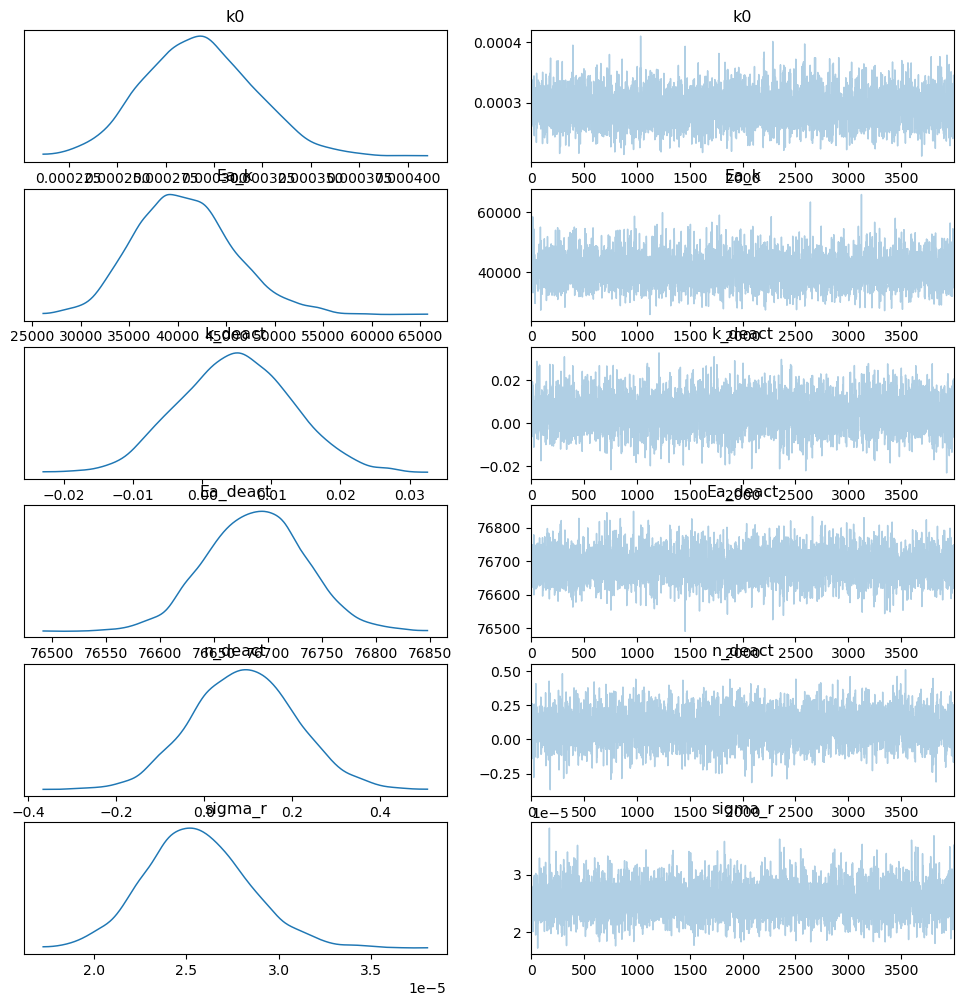

In [ ]:
import arviz as az

az.plot_trace(
    Vidata, var_names=["k0", "Ea_k", "k_deact", "Ea_deact", "n_deact", "sigma_r"]
)

In [ ]:
az.summary(
    Vidata, var_names=["k0", "Ea_k", "k_deact", "Ea_deact", "n_deact", "sigma_r"]
)

arviz - WARNING - Shape validation failed: input_shape: (1, 4000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
k0,0.000,0.000,0.000,0.000,0.000,0.000,3930.0,3660.0,NaN
Ea_k,40730.328,5055.648,31336.596,50068.480,80.185,61.771,3987.0,3575.0,NaN
k_deact,0.005,0.008,-0.010,0.020,0.000,0.000,3904.0,3103.0,NaN
Ea_deact,76688.320,45.452,76606.008,76773.430,0.731,0.522,3854.0,3097.0,NaN
n_deact,0.090,0.118,-0.135,0.301,0.002,0.001,4073.0,3877.0,NaN
sigma_r,0.000,0.000,0.000,0.000,0.000,0.000,3933.0,3359.0,NaN
